# MDP Process

Full pipeline from a scanned plate to a layered MediBang Paint (`.mdp`) file, one step per section so each layer can be hand tuned before moving on:

1. **Setup**: imports, the image to process, output folder
2. **Binarization**: ink layer (black lines on transparent)
3. **Color quantization**: flat-color layer
4. **Distinct colors & colormap**: inspect the palette, optionally remap colors
5. **Build MDP layers**: chosen colors each get their own layer, the rest share one
6. **Write MDP**: `original` (bottom), color layers (middle), `ink` (top)

## 1. Setup

(1768, 5423, 3)


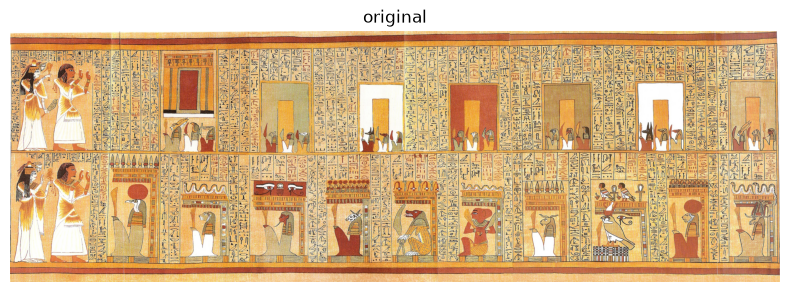

In [1]:
import struct
import time
import zlib
from pathlib import Path

import cv2
import doxapy  # https://pypi.org/project/doxapy/
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage.filters import threshold_sauvola
from sklearn.cluster import MiniBatchKMeans

# --- file to process ---
IMG_FILE = Path("/Users/sophial/Documents/Readings/BookoftheDead/papyrusani/Plate 11 Assembled 1.jpg")
# --- where the .mdp goes (file is named <image name>.mdp) ---
OUTPUT_DIR = Path("outputs")


def load_image(path):
    """Read as BGR; transparent parts of PNGs become white."""
    img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if img is None:
        raise FileNotFoundError(f"could not read {path}")
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    elif img.shape[2] == 4:
        alpha = img[:, :, 3]
        bgr = img[:, :, :3]
        white = np.full_like(bgr, 255)
        img = np.where(alpha[:, :, None] == 0, white, bgr)
    return img


def show(*imgs, titles=None, cmap="gray", size=8):
    """Show one or more images side by side (BGR color or 2D gray)."""
    fig, axes = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size), squeeze=False)
    for i, (ax, im) in enumerate(zip(axes.flat, imgs)):
        if im.ndim == 3:
            im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        ax.imshow(im, cmap=cmap)
        ax.set_title(titles[i] if titles else "")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


img = load_image(IMG_FILE)
print(img.shape)
show(img, titles=["original"])

## 2. Binarization

### 2a. Try all 12 methods
Compare every doxapy algorithm side by side, then pick one for `binarize` below.

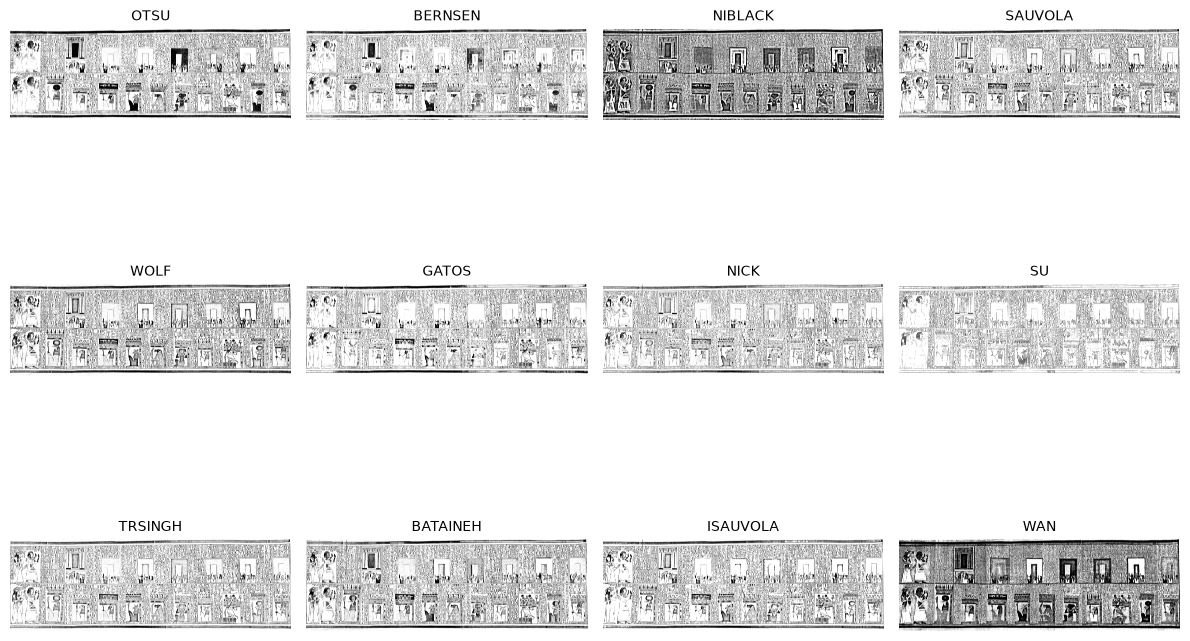

In [2]:
algorithms = ['OTSU', 'BERNSEN', 'NIBLACK', 'SAUVOLA', 'WOLF', 'GATOS', 'NICK', 'SU', 'TRSINGH', 'BATAINEH', 'ISAUVOLA', 'WAN']

def all_binarize_algos(img: np.ndarray):
    # Convert to flat 2D grayscale, no alpha (doxapy requires single-channel input)
    if img.ndim == 3:
        gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray_img = img
    all_bins = []
    for algo in algorithms:
        binary_image = np.empty(gray_img.shape, gray_img.dtype)
        # Pick an algorithm from the DoxaPy library and convert the image to binary
        facsimile = doxapy.Binarization(getattr(doxapy.Binarization.Algorithms, algo))
        facsimile.initialize(gray_img)
        facsimile.to_binary(binary_image)
        all_bins.append(binary_image)
    return all_bins

def plot_all_binarize(img: np.ndarray):
    images = all_binarize_algos(img)
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i], cmap="gray")
        ax.set_title(algorithms[i], fontsize=10)
        ax.axis('off')  # Hide axes
    plt.tight_layout()
    plt.show()

plot_all_binarize(img)

### 2b. Binarize with the chosen method
Returns a 2D array: ink = 0 (black), paper = 255 (white).

- `func`: one of the 12 algorithm names above
- `thicken`: thicken black lines by ~1px
- `despeckle`: drop ink blobs smaller than this many px (paper grain); 0 = keep all

**Optional pre-filters** (commented out in the function; uncomment to try). Both run on the grayscale image before thresholding:
- **Median filter** `cv2.medianBlur(gray, k)`: replaces each pixel with the median of a k×k window (k odd: 3, 5, 7). Very good at salt-and-pepper grain; larger k also rounds off thin lines and corners.
- **Bilateral filter** `cv2.bilateralFilter(gray, d, sigmaColor, sigmaSpace)`: smooths while keeping edges sharp, by only averaging neighbors that are both *close by* and *similar in brightness*.
  - `d`: diameter of the pixel neighborhood. 5 is fast; 9 is a good default for heavier noise. Larger is much slower. If `d <= 0` it is computed from `sigmaSpace`.
  - `sigmaColor`: how different in brightness (0-255) a neighbor can be and still get averaged in. Small (10-30) keeps even faint edges but removes little texture; large (75-150) flattens texture but starts blurring across weaker edges.
  - `sigmaSpace`: how far away (px) neighbors still have influence. Larger = smoothing over a wider area (only matters up to `d` when `d > 0`).
  - Typical starting point: `d=9, sigmaColor=75, sigmaSpace=75`. Passing it several times with a small `sigmaColor` tends to work better than one pass with a large one.

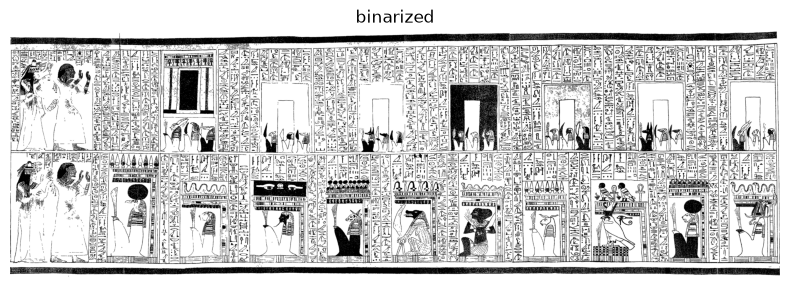

In [3]:
def binarize(img: np.ndarray, func="WOLF", thicken=False, despeckle=20):
    # Convert to flat 2D grayscale, no alpha (doxapy requires single-channel input)
    if img.ndim == 3:
        gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray_img = img

    # --- optional pre-filtering (see notes above) ---
    # gray_img = cv2.medianBlur(gray_img, 5)   # median: kernel size k (odd)
    # gray_img = cv2.bilateralFilter(gray_img, d=9, sigmaColor=75, sigmaSpace=75)  # bilateral

    # binarize
    binary_image = np.empty(gray_img.shape, gray_img.dtype)
    facsimile = doxapy.Binarization(getattr(doxapy.Binarization.Algorithms, func))
    facsimile.initialize(gray_img)
    facsimile.to_binary(binary_image)

    # Thicken black lines
    if thicken:
        kernel = np.ones((3, 3), np.uint8)
        binary_image = cv2.erode(binary_image, kernel, iterations=1)

    # binary_image = cv2.medianBlur(binary_image, 5)   # median: kernel size k (odd)

    # Drop small ink specks (paper grain)
    if despeckle:
        ink = binary_image == 0
        _, lab, stats, _ = cv2.connectedComponentsWithStats(ink.astype(np.uint8), connectivity=8)
        small = stats[:, cv2.CC_STAT_AREA] < despeckle
        small[0] = False
        binary_image[small[lab] & ink] = 255

    return binary_image

binary = binarize(img, func="OTSU", thicken=False, despeckle=10)
show(binary, titles=["binarized"])

## 3. Color quantization

Reduces the scan to at most `n` flat colors, using the dark outlines as walls for where color blobs begin and end:

1. Denoise (median → bilateral passes → mean-shift) so blobs flatten but outlines stay sharp.
2. Find the ink (locally dark via Sauvola, or globally very dark). Ink becomes one color.
3. K-means on the non-ink pixels picks the other n-1 colors (lightness down-weighted so paper shading doesn't hog colors), then near-duplicates merge, so `n` is a maximum. Or pass a fixed `palette_hex` list instead.
4. Clean labels: small ink-enclosed regions get one majority color, a majority filter removes grain, specks below `min_area` are absorbed.

### 3a. Helpers

In [4]:
def denoise(bgr: np.ndarray, strength: int, spatial: int, color: int) -> np.ndarray:
    """Median to kill salt/pepper grain, bilateral passes to calm texture,
    then mean-shift to pull each area toward its dominant color."""
    out = cv2.medianBlur(bgr, 5)
    for _ in range(strength):
        out = cv2.bilateralFilter(out, d=9, sigmaColor=30, sigmaSpace=9)
    return cv2.pyrMeanShiftFiltering(out, sp=spatial, sr=color)


def ink_mask(bgr: np.ndarray, window: int, k: float, dark_pct: float, max_gray: int,
             min_ink: int) -> np.ndarray:
    """Boolean mask of outline/ink pixels."""
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    # Local threshold finds thin lines, but at the edge of a dark paint area
    # (red next to pale paper) it also flags the paint; requiring real
    # darkness keeps only the ink
    local = (gray < threshold_sauvola(gray, window_size=window, k=k)) & (gray < max_gray)
    # Sauvola misses the interior of large solid black areas; catch those globally
    dark = gray < np.percentile(gray, dark_pct)
    return remove_small(local | dark, min_ink)


def remove_small(mask: np.ndarray, min_area: int) -> np.ndarray:
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    keep = stats[:, cv2.CC_STAT_AREA] >= min_area
    keep[0] = False
    return keep[lab]


def fit_palette(lab_px: np.ndarray, k: int, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    sample = lab_px[rng.choice(len(lab_px), size=min(200_000, len(lab_px)), replace=False)]
    km = MiniBatchKMeans(n_clusters=k, random_state=seed, n_init=5, batch_size=4096).fit(sample)
    return km.cluster_centers_


def merge_close(centers: np.ndarray, counts: np.ndarray, thresh: float) -> np.ndarray:
    """Greedily merge the closest pair of centers (count-weighted) until every
    pair is at least thresh apart. Returns the surviving centers."""
    centers, counts = list(centers), list(counts.astype(float))
    while len(centers) > 1:
        c = np.array(centers)
        d = np.sqrt(((c[:, None] - c[None]) ** 2).sum(-1))
        np.fill_diagonal(d, np.inf)
        i, j = np.unravel_index(d.argmin(), d.shape)
        if d[i, j] >= thresh:
            break
        tot = counts[i] + counts[j]
        centers[i] = (centers[i] * counts[i] + centers[j] * counts[j]) / max(tot, 1)
        counts[i] = tot
        del centers[j], counts[j]
    return np.array(centers)


def assign(lab_px: np.ndarray, centers: np.ndarray) -> np.ndarray:
    labels = np.empty(len(lab_px), dtype=np.int32)
    for i in range(0, len(lab_px), 1_000_000):
        chunk = lab_px[i:i + 1_000_000]
        d = ((chunk[:, None, :] - centers[None, :, :]) ** 2).sum(-1)
        labels[i:i + 1_000_000] = d.argmin(1)
    return labels


def majority_filter(labels: np.ndarray, valid: np.ndarray, n: int, size: int) -> np.ndarray:
    """Per-pixel mode over a size x size window, counting only valid (non-ink)
    pixels so colors don't bleed across outlines."""
    best = np.full(labels.shape, -1.0, dtype=np.float32)
    out = labels.copy()
    for c in range(n):
        votes = cv2.boxFilter(((labels == c) & valid).astype(np.float32), -1, (size, size), normalize=False)
        better = votes > best
        best[better] = votes[better]
        out[better] = c
    out[~valid] = labels[~valid]
    return out


def fill_regions(labels: np.ndarray, ink: np.ndarray, n: int, max_region: int) -> np.ndarray:
    """Every ink-enclosed region smaller than max_region gets its majority color."""
    nreg, reg = cv2.connectedComponents((~ink).astype(np.uint8), connectivity=4)
    counts = np.zeros((nreg, n), dtype=np.int64)
    np.add.at(counts, (reg[~ink], labels[~ink]), 1)
    sizes = counts.sum(1)
    small = (sizes > 0) & (sizes < max_region)
    small[0] = False if ink[reg == 0].all() else small[0]
    majority = counts.argmax(1)
    out = labels.copy()
    sel = small[reg] & ~ink
    out[sel] = majority[reg[sel]]
    return out


def absorb_specks(labels: np.ndarray, ink: np.ndarray, n: int, min_area: int) -> np.ndarray:
    """Blobs (per color) smaller than min_area are replaced by the nearest
    surviving non-ink pixel's color."""
    keep = ink.copy()
    for c in range(n):
        m = (labels == c) & ~ink
        keep |= remove_small(m, min_area)
    if keep.all():
        return labels
    # nearest kept non-ink pixel
    src = keep & ~ink
    _, (iy, ix) = ndimage.distance_transform_edt(~src, return_indices=True)
    out = labels.copy()
    fix = ~keep
    out[fix] = labels[iy[fix], ix[fix]]
    return out


def parse_hex(colors: list[str]) -> np.ndarray:
    rgb = np.array([[int(h.lstrip("#")[i:i + 2], 16) for i in (0, 2, 4)] for h in colors], dtype=np.uint8)
    return rgb


def to_lab(rgb_or_bgr: np.ndarray, code: int) -> np.ndarray:
    return cv2.cvtColor(rgb_or_bgr.reshape(-1, 1, 3), code).reshape(-1, 3).astype(np.float32)

### 3b. Quantize
Tunable parameters:
- `n`: max colors including ink; `palette_hex`: fixed list of hex colors to snap to instead of k-means (darkest = ink)
- `strength`: bilateral denoise passes; `ms_spatial` / `ms_color`: mean-shift spatial radius (px) / color radius (higher = flatter)
- `l_weight`: weight of lightness vs. hue when clustering (lower ignores shading more); `merge`: merge colors closer than this (0 = keep exactly n)
- `sauvola_window` (odd) / `sauvola_k` (higher = less ink); `dark_pct`: percentile of gray that is always ink; `ink_max_gray`: outline ink must be darker than this (raise if faint lines vanish); `min_ink`: drop ink specks smaller than this (px)
- `smooth`: majority filter window (px); `max_region`: ink-enclosed regions smaller than this get one color (px); `min_area`: color blobs smaller than this get absorbed (px)

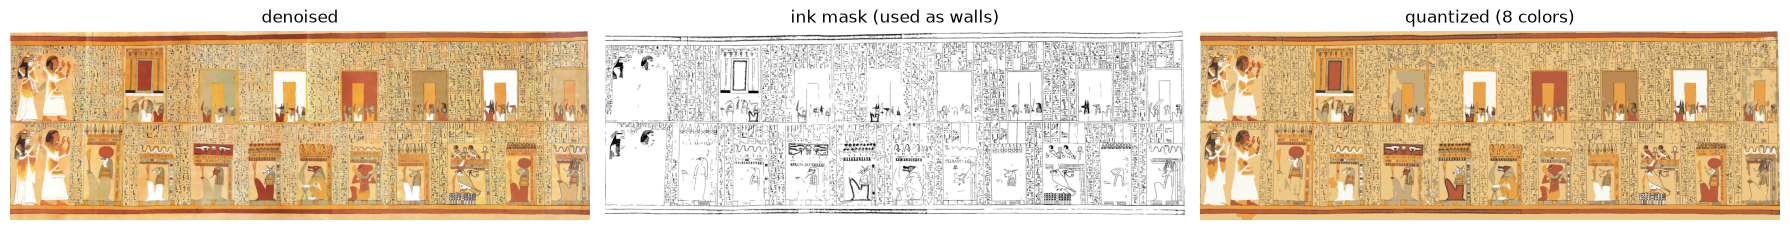

<Figure size 800x100 with 0 Axes>

<Figure size 800x100 with 0 Axes>

In [5]:
def quantize(img_bgr, n, palette_hex=None, strength=3, ms_spatial=12, ms_color=20, l_weight=0.35, merge=14.0,
             sauvola_window=31, sauvola_k=0.15, dark_pct=6.0, ink_max_gray=105, min_ink=30, smooth=9,
             max_region=4000, min_area=80, seed=0):
    h, w = img_bgr.shape[:2]
    smooth_bgr = denoise(img_bgr, strength, ms_spatial, ms_color)
    lab = to_lab(smooth_bgr, cv2.COLOR_BGR2LAB).reshape(h, w, 3)
    ink = ink_mask(img_bgr, sauvola_window, sauvola_k, dark_pct, ink_max_gray, min_ink)
    # Cluster with lightness down-weighted, so shading/staining in the paper
    # doesn't eat up colors that should go to actual hue differences
    wts = np.array([l_weight, 1.0, 1.0], dtype=np.float32)

    if palette_hex:
        pal_rgb = parse_hex(palette_hex)
        pal_lab = to_lab(pal_rgb, cv2.COLOR_RGB2LAB)
        ink_idx = int(pal_lab[:, 0].argmin())  # darkest palette color is ink
    else:
        paper = lab[~ink] * wts
        centers = fit_palette(paper, n - 1, seed)
        if merge > 0:
            sample = paper[::max(1, len(paper) // 500_000)]
            counts = np.bincount(assign(sample, centers), minlength=len(centers))
            centers = merge_close(centers, counts, merge)
        # ink color from the darkest core of the strokes, not their soft edges
        ink_px = lab[ink]
        core = ink_px[ink_px[:, 0] <= np.percentile(ink_px[:, 0], 30)]
        pal_lab = np.vstack([centers / wts, np.median(core, axis=0)])
        ink_idx = len(pal_lab) - 1
    k = len(pal_lab)

    labels = assign(lab.reshape(-1, 3) * wts, pal_lab * wts).reshape(h, w)
    labels[ink] = ink_idx

    labels = fill_regions(labels, ink, k, max_region)
    labels = majority_filter(labels, ~ink, k, smooth)
    labels = absorb_specks(labels, ink, k, min_area)

    if not palette_hex:
        pal_rgb = cv2.cvtColor(pal_lab.reshape(-1, 1, 3).round().astype(np.uint8),
                               cv2.COLOR_LAB2RGB).reshape(-1, 3)
    return pal_rgb[labels], pal_rgb, {"denoised": smooth_bgr, "ink": ink}

colors_rgb, palette, dbg = quantize(img, n=10)
colors = cv2.cvtColor(colors_rgb, cv2.COLOR_RGB2BGR)

# print("palette:", " ".join(f"#{r:02x}{g:02x}{b:02x}" for r, g, b in palette))
show(dbg["denoised"], np.where(dbg["ink"], 0, 255).astype(np.uint8), colors,
     titles=["denoised", "ink mask (used as walls)", f"quantized ({len(palette)} colors)"], size=6)
plt.figure(figsize=(len(palette), 1))
# plt.imshow(palette[None]); plt.axis("off"); plt.show()

## 4. Distinct colors & colormap

### 4a. Plot all distinct colors
Every distinct color in the quantized image, most common first.

['#edc887', '#e9a248', '#49392d', '#b75d3e', '#f9f9f2', '#c4ac7e', '#bb8953', '#8b7a65']


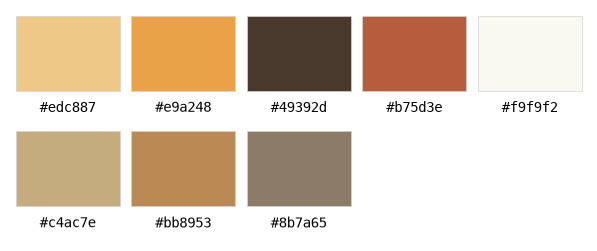

In [6]:
def get_colors(img_bgr: np.ndarray):
    """Hex codes of every distinct color, most common first."""
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).reshape(-1, 3)
    uniq, counts = np.unique(rgb, axis=0, return_counts=True)
    return ['#%02x%02x%02x' % tuple(c) for c in uniq[np.argsort(-counts)]]

def plot_colors(color_info, n=5):
    """Swatches, n per row, each with its hex code written underneath."""
    cols = min(n, len(color_info))
    rows = -(-len(color_info) // n)  # ceil division
    fig, ax = plt.subplots(figsize=(cols * 1.5, rows * 1.5))
    ax.set_xlim(0, cols)
    ax.set_ylim(0, rows)
    ax.set_aspect("equal")
    ax.axis("off")

    for i, hex_code in enumerate(color_info):
        col = i % n
        y = rows - 1 - i // n  # top row first
        # swatch fills the top of the cell, label sits in the strip below it
        ax.add_patch(plt.Rectangle((col + 0.05, y + 0.3), 0.9, 0.65,
                                   facecolor=hex_code, edgecolor="lightgray", linewidth=0.5))
        ax.text(col + 0.5, y + 0.15, hex_code, ha="center", va="center", fontsize=10, family="monospace")

    plt.show()

color_list = get_colors(colors)
print(color_list)
plot_colors(color_list)

### 4b. Colormap (optional)
Replace colors with new ones: `{"#old": "#new"}`. Leave `COLOR_MAP` empty to skip; `mapped` is then just `colors`.
Mapping two colors to the same new color merges them.

In [7]:
def hex_to_rgb(hex_color):
    """Converts hexadecimal color representation to RGB."""
    hex_color = hex_color.strip("#")
    return tuple(int(hex_color[i:i + 2], 16) for i in (0, 2, 4))

def plot_color_map(color_map):
    fig, ax = plt.subplots(len(color_map), 2, figsize=(4, len(color_map) * 2))
    ax = ax.reshape(len(color_map), 2)
    for i, (orig, new) in enumerate(color_map.items()):
        for j, color in enumerate([orig, new]):
            ax[i, j].add_patch(plt.Rectangle((0, 0), 1, 1, color=color))
            ax[i, j].set_title(color, fontsize=10)
            ax[i, j].axis("off")
    plt.tight_layout()
    plt.show()

def apply_color_mapping(img_bgr: np.ndarray, color_map):
    out = img_bgr.copy()
    for orig, new in color_map.items():
        match = np.all(img_bgr == hex_to_rgb(orig)[::-1], axis=-1)  # compare against the original, BGR order
        out[match] = hex_to_rgb(new)[::-1]
    return out

COLOR_MAP = {
    # "#edb656": "#e5a040",
}

mapped = apply_color_mapping(colors, COLOR_MAP)
if COLOR_MAP:
    plot_color_map(COLOR_MAP)
    show(colors, mapped, titles=["before", "after colormap"], size=6)
    plot_colors(get_colors(mapped))

## 5. Build MDP layers

By default (`LAYER_COLORS = []`) all colors stay in a single `colors` layer.
List hex codes in `LAYER_COLORS` to give each of those colors its own layer (named by its hex code); everything else stays together in one `other colors` layer.
Copy hex codes from the 4a/4b plots. Colors not present in the image are skipped with a warning.

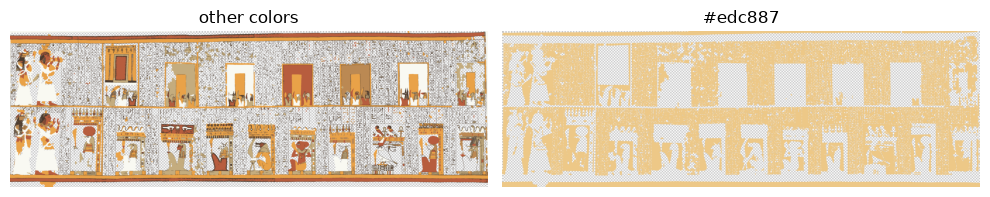

In [10]:
def to_bgra(img_bgr: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2BGRA)


def ink_to_bgra(binary: np.ndarray) -> np.ndarray:
    """Black ink on a transparent background, as straight-alpha BGRA."""
    out = np.zeros((*binary.shape, 4), np.uint8)
    out[..., 3] = np.where(binary == 255, 0, 255)
    return out


def composite(layers: list[np.ndarray]) -> np.ndarray:
    """Alpha-over composite of straight-alpha BGRA layers, bottom first."""
    out = np.zeros(layers[0].shape[:2] + (3,), np.float32)
    for lay in layers:
        a = lay[..., 3:4].astype(np.float32) / 255
        out = lay[..., :3] * a + out * (1 - a)
    return out.round().astype(np.uint8)


def split_color_layers(img_bgr: np.ndarray, layer_colors, rest_name="other colors"):
    """One BGRA layer per listed hex color, plus one layer with all leftover
    pixels. Returns (name, BGRA) pairs, leftover first (= lowest). With no
    layer_colors, everything stays in a single "colors" layer."""
    bgra = to_bgra(img_bgr)
    if not layer_colors:
        return [("colors", bgra)]
    taken = np.zeros(img_bgr.shape[:2], bool)
    color_layers = []
    for hex_code in layer_colors:
        match = np.all(img_bgr == hex_to_rgb(hex_code)[::-1], axis=-1)
        if not match.any():
            print(f"warning: {hex_code} not in image, skipped")
            continue
        lay = bgra.copy()
        lay[~match, 3] = 0
        color_layers.append((hex_code, lay))
        taken |= match
    rest = bgra.copy()
    rest[taken, 3] = 0
    return [(rest_name, rest)] + color_layers


LAYER_COLORS = ["#edc887"]  # e.g. ["#ca6d4b", "#edb656"]; empty = all colors stay in one layer

color_layers = split_color_layers(mapped, LAYER_COLORS)

def checker(h, w, s=16):
    """Gray checkerboard so transparency is visible."""
    yy, xx = np.mgrid[:h, :w]
    return np.where(((yy // s + xx // s) % 2)[..., None] == 0, 200, 255).astype(np.uint8).repeat(3, -1)

bg = to_bgra(checker(*mapped.shape[:2]))
show(*[composite([bg, lay]) for _, lay in color_layers],
     titles=[name for name, _ in color_layers], size=5)

## 6. Write MDP

Layers, bottom to top: `original`, the color layers from section 5 (one `colors` layer by default, or `other colors` + one per `LAYER_COLORS` entry), `ink` (section 2, black on transparent).
Saved as `<OUTPUT_DIR>/<image name>.mdp`; set `OUTPUT_DIR` in Setup to change the folder.

.mdp layout (reverse-engineered from MediBang Paint Pro files):
`"mdipack\0"` + u32 0 + u32 xml_len + u32 bin_len, then the XML, then `"PAC "` chunks: u32 chunk_len, u32 zlib_flag, u32 data_len, u32 raw_len, 48 zero bytes, 64-byte name, data. A layer chunk is u32 n_tiles, u32 tile_size (128), then per tile u32 x, u32 y, u32 0, u32 len and a zlib stream of straight-alpha BGRA, padded to 4 bytes. Layers are listed bottom to top. The thumbnail is one plain zlib BGRA chunk.

wrote outputs/Plate 11 Assembled 1.mdp (31.3 MB)


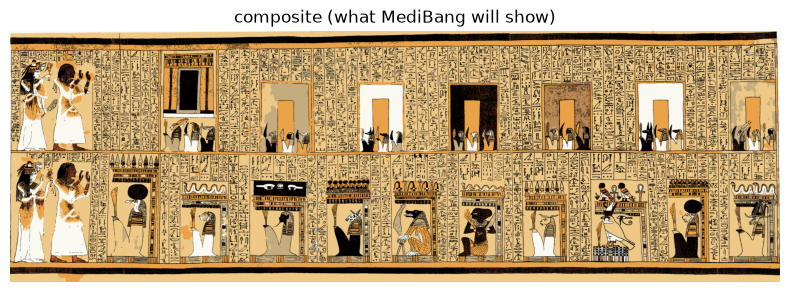

In [11]:
TILE = 128
THUMB_MAX = 256


def pac_chunk(name: str, data: bytes, zlib_flag: int, raw_len: int) -> bytes:
    header = b"PAC " + struct.pack("<4I", 132 + len(data), zlib_flag, len(data), raw_len)
    return header + bytes(48) + name.encode().ljust(64, b"\0") + data


def layer_data(bgra: np.ndarray) -> bytes:
    """Tile the layer, skipping fully transparent tiles."""
    h, w = bgra.shape[:2]
    tiles = []
    for ty in range(0, (h + TILE - 1) // TILE):
        for tx in range(0, (w + TILE - 1) // TILE):
            tile = bgra[ty * TILE:(ty + 1) * TILE, tx * TILE:(tx + 1) * TILE]
            if not tile[..., 3].any():
                continue
            if tile.shape[:2] != (TILE, TILE):
                padded = np.zeros((TILE, TILE, 4), np.uint8)
                padded[:tile.shape[0], :tile.shape[1]] = tile
                tile = padded
            comp = zlib.compress(np.ascontiguousarray(tile).tobytes(), 6)
            pad = -len(comp) % 4
            tiles.append(struct.pack("<4I", tx, ty, 0, len(comp)) + comp + bytes(pad))
    if not tiles:
        return struct.pack("<I", 0)
    return struct.pack("<II", len(tiles), TILE) + b"".join(tiles)


def write_mdp(path: Path, layers: list[tuple[str, np.ndarray]], dpi: int = 300) -> None:
    """layers: (name, BGRA array) pairs, bottom to top."""
    h, w = layers[0][1].shape[:2]
    scale = THUMB_MAX / max(w, h)
    tw, th = max(1, round(w * scale)), max(1, round(h * scale))
    thumb = cv2.resize(to_bgra(composite([l for _, l in layers])), (tw, th), interpolation=cv2.INTER_AREA)

    chunks = [pac_chunk("thumb", zlib.compress(thumb.tobytes(), 6), 1, thumb.nbytes)]
    layer_xml = []
    for i, (name, bgra) in enumerate(layers):
        data = layer_data(bgra)
        chunks.append(pac_chunk(f"layer{i}img", data, 0, len(data)))
        layer_xml.append(
            f'        <Layer ofsx="0" ofsy="0" width="{w}" height="{h}" mode="normal" alpha="255" '
            f'visible="true" protectAlpha="false" locked="false" clipping="false" masking="false" '
            f'maskingType="0" group="-1" id="{i}" draft="false" parentId="-1" name="{name}" '
            f'binType="2" bin="layer{i}img" type="32bpp" />'
        )

    now = int(time.time())
    stamp = time.strftime("%Y-%m-%dT%H:%M:%S", time.localtime(now))
    xml = (
        '<?xml version="1.0" encoding="UTF-8" ?>\n'
        f'<Mdiapp width="{w}" height="{h}" dpi="{dpi}" checkerBG="true" '
        'bgColorR="255" bgColorG="255" bgColorB="255">\n'
        f'    <CreateTime time="{now}" timeString="{stamp}" />\n'
        f'    <UpdateTime time="{now}" timeString="{stamp}" rev="1" />\n'
        f'    <Thumb width="{tw}" height="{th}" bin="thumb" />\n'
        '    <Snaps />\n'
        '    <Guides />\n'
        f'    <Layers active="{len(layers) - 1}">\n'
        + "\n".join(layer_xml) + "\n"
        '    </Layers>\n'
        '    <appInfo name="MediBang Paint Pro" rev="86" bitType="64" />\n'
        '</Mdiapp>\n'
    ).encode()
    body = b"".join(chunks)
    path.write_bytes(b"mdipack\0" + struct.pack("<3I", 0, len(xml), len(body)) + xml + body)


layers = [("original", to_bgra(img))] + color_layers + [("ink", ink_to_bgra(binary))]
out_path = OUTPUT_DIR / f"{IMG_FILE.stem}.mdp"
out_path.parent.mkdir(parents=True, exist_ok=True)
write_mdp(out_path, layers, dpi=300)
print(f"wrote {out_path} ({out_path.stat().st_size / 1e6:.1f} MB)")
show(composite([l for _, l in layers]), titles=["composite (what MediBang will show)"])